# 03. Phân tích Lỗi (Error Analysis) & Khuyến nghị Ứng dụng
**Nhóm 12 — Đề tài 12:** Phát hiện giao dịch thẻ tín dụng gian lận  
**Mục tiêu:** Phân tích chi tiết các ca **False Negative (FN – bỏ sót gian lận)** và **False Positive (FP – cảnh báo nhầm khách hàng)** trên tập Test Luồng B, liên hệ với đặc điểm phân phối dữ liệu và giả định của từng thuật toán.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
with (PROJECT_ROOT / "outputs" / "metrics" / "error_analysis.json").open("r", encoding="utf-8") as f:
    err = json.load(f)

print("Mô hình chính được phân tích:", err["primary_model"])
print("\nThống kê theo nhóm TP / FN / FP / TN:")
display(pd.DataFrame(err["outcome_stats"]).T[["count", "amount_sum", "amount_mean", "amount_median"]])

print("\nKhả năng bắt gian lận (trên 95 ca gian lận Test Luồng B) giữa các mô hình:")
display(pd.DataFrame(err["fraud_detection_by_model"]).T)

Mô hình chính được phân tích: Random Forest (Mở rộng)

Thống kê theo nhóm TP / FN / FP / TN:


,count,amount_sum,amount_mean,amount_median
TP,68,8892.11,130.77,34.3
FN,27,5874.2,217.56,3.76
FP,3,200.89,66.96,89.99
TN,56648,5024925.0,88.7,21.6



Khả năng bắt gian lận (trên 95 ca gian lận Test Luồng B) giữa các mô hình:


,caught_tp,missed_fn
K-NN (Tuned),64,31
Gaussian Naive Bayes,78,17
Decision Tree (Tuned),61,34
Random Forest (Mở rộng),68,27
HistGradientBoosting (Mở rộng),68,27


### Phân tích tổng quan các nhóm dự đoán (TP, FN, FP, TN)
Trên 56.746 giao dịch tập Test của Luồng B (gồm 95 giao dịch gian lận thực tế), mô hình chính **`Random Forest (Mở rộng)`** (ngưỡng `0.55`) đạt:
- **68 True Positive (TP):** Bắt được 71.58% số vụ gian lận, tổng giá trị ngăn chặn được là **$8,892.11** (trung vị **$34.30**).
- **27 False Negative (FN):** Bỏ sót 28.42% số vụ gian lận với tổng giá trị **$5,874.20** (giá trị trung bình lên tới **$217.56**, dù trung vị nhỏ là **$3.76** — cho thấy có một số ít giao dịch gian lận giá trị lớn bị lọt lưới).
- **3 False Positive (FP):** Chỉ báo nhầm **3 / 56,651** giao dịch hợp lệ (**0.0053%**), giúp trải nghiệm khách hàng gần như không bị gián đoạn.
- **Đối chiếu đa mô hình:** `Gaussian Naive Bayes` bắt được nhiều ca gian lận nhất (**78/95** ca), nhưng phải trả giá bằng **1,490–1,567 FP**; trong khi `K-NN (Tuned)` (ở ngưỡng `0.55` sau threshold tuning) bắt `64/95` (4 FP; so với `66/95` ở ngưỡng mặc định `0.50`) và `Decision Tree (Tuned)` bắt `61/95` (5 FP).

Top 5 giao dịch gian lận giá trị lớn bị bỏ sót (False Negative):


,Time,Hour,Amount,V17,V14,V12,V10,y_prob
0,9064.0,2.0,1809.68,-5.1361,-3.7380,-6.9980,-1.9878,0.3831
1,154309.0,18.0,1096.99,-0.0524,0.9850,0.9797,-1.1345,0.0071
2,131024.0,12.0,723.21,1.1657,-2.3066,-0.0544,0.0857,0.0579
3,67571.0,18.0,549.06,0.2433,0.2175,-0.0054,-1.7691,0.0000
4,52814.0,14.0,519.90,-0.1192,0.5789,-0.7960,-0.1501,0.0000



Các giao dịch hợp lệ bị báo nhầm (False Positive):


,Time,Hour,Amount,V17,V14,V12,V10,y_prob
0,75706.0,21.0,109.90,-12.1293,-7.1096,-7.1045,-5.6220,0.9829
1,41444.0,11.0,1.00,-7.7819,-8.2474,-6.9627,-6.3841,0.8080
2,17789.0,4.0,89.99,-16.8253,-13.6241,-15.1179,-11.1529,0.5912



Số ca gian lận khó (bị bỏ sót bởi hầu hết mô hình): 26


,test_row_pos,Amount,Hour,V17,V14,V12,missed_by
0,51417,1809.68,2.0,-5.1361,-3.7380,-6.9980,"[K-NN (Tuned), Decision Tree (Tuned), Random F..."
1,4480,1096.99,18.0,-0.0524,0.9850,0.9797,"[K-NN (Tuned), Gaussian Naive Bayes, Decision ..."
2,44579,723.21,12.0,1.1657,-2.3066,-0.0544,"[K-NN (Tuned), Gaussian Naive Bayes, Decision ..."
3,47606,549.06,18.0,0.2433,0.2175,-0.0054,"[K-NN (Tuned), Gaussian Naive Bayes, Decision ..."
4,54283,519.90,14.0,-0.1192,0.5789,-0.7960,"[K-NN (Tuned), Gaussian Naive Bayes, Decision ..."


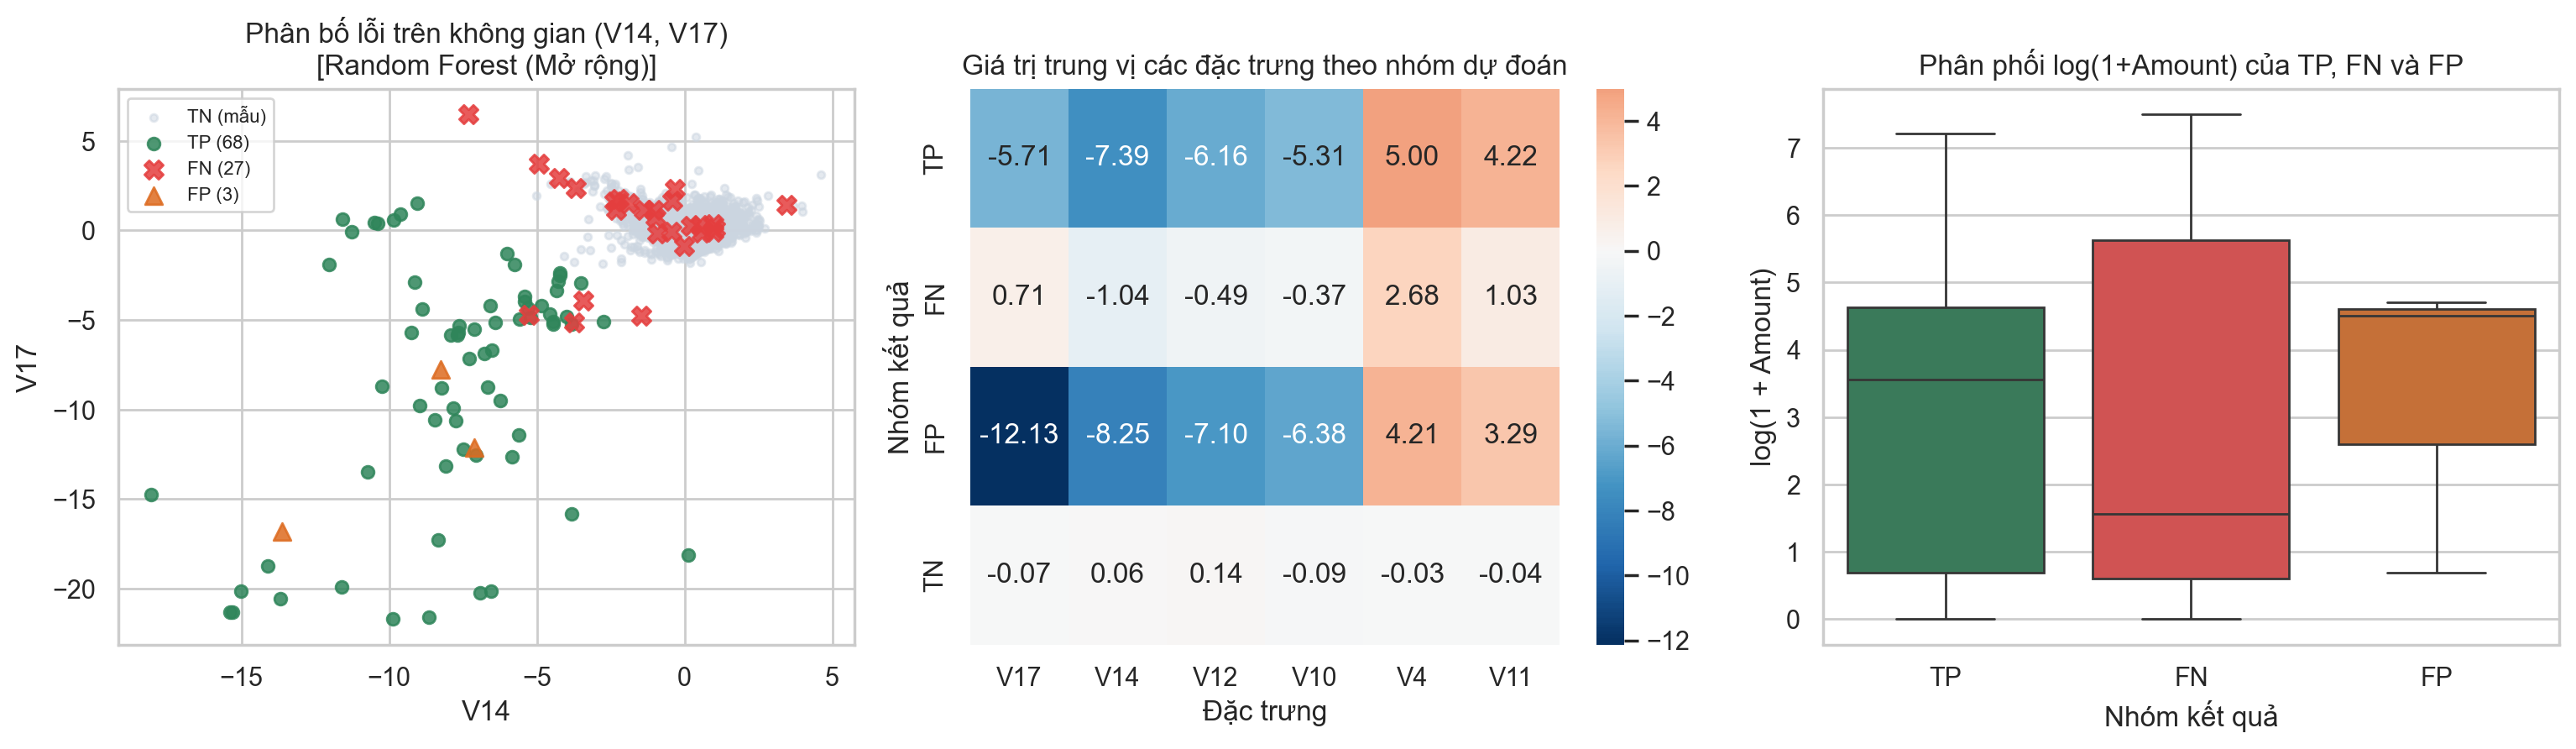

In [2]:
print("Top 5 giao dịch gian lận giá trị lớn bị bỏ sót (False Negative):")
display(pd.DataFrame(err["top_fn_high_amount"]))

print("\nCác giao dịch hợp lệ bị báo nhầm (False Positive):")
display(pd.DataFrame(err["top_fp_high_confidence"]))

print(f"\nSố ca gian lận khó (bị bỏ sót bởi hầu hết mô hình): {err['hard_fraud_cases_count']}")
display(pd.DataFrame(err["sample_hard_fraud_cases"]))

p = PROJECT_ROOT / "outputs" / "figures" / "error_analysis_fn_fp.png"
if p.is_file():
    display(Image(filename=str(p)))

### Giải thích nguyên nhân gốc rễ từ dữ liệu và giả định thuật toán
1. **Vì sao xuất hiện 27 ca False Negative (đặc biệt 26 ca khó)?**
   - Biểu đồ phân tán `(V14, V17)` và bảng trung vị cho thấy rõ sự khác biệt cực lớn: nhóm **TP** có trung vị `V17 = -5.71, V14 = -7.39, V12 = -6.16, V10 = -5.31`, trong khi nhóm **FN** có trung vị `V17 = +0.71, V14 = -1.04, V12 = -0.49, V10 = -0.37` — **nằm lọt vào vùng dày đặc của giao dịch hợp lệ (TN: `V17 = -0.07, V14 = +0.06`)**.
   - Ví dụ điển hình như ca `test_row_pos = 4480` (`Amount = $1,096.99`, `V17 = -0.0524, V14 = +0.985, V12 = +0.9797`): bị **cả 5 mô hình** dự đoán nhầm là hợp lệ vì ở cấp độ *từng giao dịch đơn lẻ*, hồ sơ PCA không mang dấu hiệu bất thường.
   - Riêng ca `Time = 9064s` (`Amount = $1,809.68`, `Hour = 2h` sáng, `V17 = -5.1361, V12 = -6.998`) có xác suất từ Random Forest là **`0.3831`**, bị loại chỉ vì ngưỡng cắt hiện tại là `0.55` (và bị K-NN/DT bỏ sót do thiếu hàng xóm gần có cùng mức tiền cao vào 2h sáng).
2. **Vì sao xuất hiện 3 ca False Positive?**
   - Cả 3 giao dịch hợp lệ bị cảnh báo nhầm đều có các thành phần PCA âm rất sâu giống hệt khuôn mẫu gian lận (trung vị nhóm FP: `V17 = -12.13, V14 = -8.25, V12 = -7.10, V10 = -6.38`), ví dụ ca `Time = 75706s` (`Amount = $109.90`, `y_prob = 0.9829`). Khi dữ liệu thiếu thông tin chuỗi hành vi chủ thẻ (tần suất quẹt thẻ trong 5 phút gần nhất, thiết bị, địa điểm), mọi bộ phân loại tĩnh đều không thể tách rời hoàn toàn 3 điểm này.

---

### Kết luận & Khuyến nghị triển khai thực tế
1. **Chiến lược phân tầng ngưỡng (Two-tier Thresholding):** Không nên dùng một ngưỡng cứng `0.55` cho mọi giao dịch. Nên thiết lập **ngưỡng mềm (`0.25–0.35`)** đối với các giao dịch **giá trị lớn hoặc vào khung giờ rủi ro cao (`~2h`, `~11h`)** để kích hoạt **xác thực OTP / 3D Secure** (sẽ bắt được ca `$1,809.68` với `y_prob = 0.3831`), và ngưỡng cao (`>= 0.80`) để tự động tạm khóa thẻ.
2. **Hạn chế của dữ liệu hiện tại & Hướng cải tiến:** Bộ dữ liệu chỉ có 48 giờ và các đặc trưng PCA rời rạc theo từng giao dịch đơn. Để giảm nhóm 26 ca FN "ẩn mình", cần bổ sung đặc trưng chuỗi theo mã thẻ (`card_id`): tốc độ giao dịch (*velocity features* trong 1h/24h), chênh lệch với mức chi tiêu trung bình của chính chủ thẻ, và khoảng cách địa lý.